**PROJECT 34:**

Jaakko Hietikko 2214871

Jani-Matti Laasonen Y68417011

Urho Väyrynen 2214968

**1. Data Exploration and Preprocessing:** Explore the distribution of tweets by sentiment, Age of User,
Country, and Time of Tweet. Visualize the data using appropriate charts such as bar charts, histograms,
and heatmaps. 

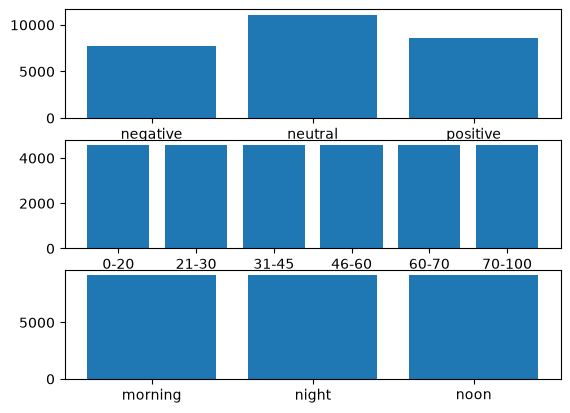

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

data = pd.read_csv("train.csv", encoding="latin1")
data_sentiment = data["sentiment"]
data_age_of_user = data["Age of User"]
data_country = data["Country"]
data_time_of_tweet = data["Time of Tweet"]
data_density = data["Density (P/Km²)"]
y = data_sentiment.value_counts().sort_index()
z = data_age_of_user.value_counts().sort_index()
x = data_country.value_counts().sort_index()
i = data_time_of_tweet.value_counts().sort_index()
j = data_density.value_counts().sort_index()

fig, ax = plt.subplots(3)

ax[0].bar(y.index, y.values)
ax[1].bar(z.index, z.values)
ax[2].bar(i.index, i.values)

plt.show()

country_df = x.rename_axis("Country").reset_index(name="Count")

fig = px.choropleth(
    country_df,
    locations="Country",
    locationmode="country names",
    color="Count",
    hover_name="Country",
    color_continuous_scale="Viridis",
    title="Number of Instances per Country"
)

fig.show()

**2. Exploratory Analysis of Demographics:** Analyze the correlation between demographic
information (e.g., Age of User, Country) and the sentiment of the tweets. Identify if certain age groups
or countries tend to express more positive, negative, or neutral sentiments. Also. analyze how density
affects sentiment patterns.

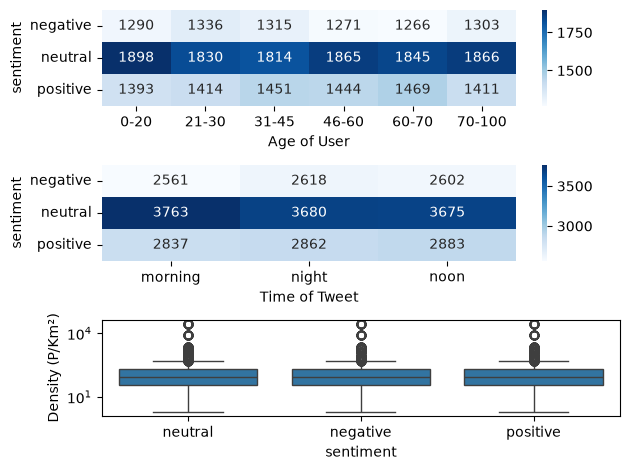

Spearman correlation between sentiment and time of tweet: 0.000
P-value: 0.9477
Spearman correlation between sentiment and age of user: 0.006
P-value: 0.3156
Spearman correlation between sentiment and density: 0.003
P-value: 0.5747


In [3]:
import numpy as np
import seaborn as sns
from scipy.stats import spearmanr

cross_table = pd.crosstab(data_sentiment, data_age_of_user)
cross_table2 = pd.crosstab(data_sentiment, data_time_of_tweet)
cross_table3 = pd.crosstab(data_sentiment, data_density)

fig, ax = plt.subplots(3)

sns.heatmap(cross_table, annot=True, fmt="d", cmap="Blues", ax=ax[0])
sns.heatmap(cross_table2, annot=True, fmt="d", cmap="Blues", ax=ax[1])
sns.boxplot(data=data, x="sentiment",y="Density (P/Km²)", ax=ax[2])
ax[2].set_yscale("log")

plt.tight_layout()
plt.show()

def correlation(data1, data2, subject1, subject2):
    rho, p_value = spearmanr(
        data1,
        data2,
        nan_policy="omit"
    )
    
    print(f"Spearman correlation between {subject1} and {subject2}: {rho:.3f}")
    print(f"P-value: {p_value:.4f}")

correlation(data["sentiment"], data["Time of Tweet"], "sentiment", "time of tweet")
correlation(data["sentiment"], data["Age of User"], "sentiment", "age of user")
correlation(data["sentiment"], data["Density (P/Km²)"], "sentiment", "density")

**3. Time of Tweet and Sentiment Trends:** Investigate how the time of tweet (morning, noon, night)
correlates with sentiment. Do people tend to tweet more positively or negatively at certain times of the
day? Visualize sentiment trends over time to identify any patterns (e.g., higher negativity during late
hours or weekends)

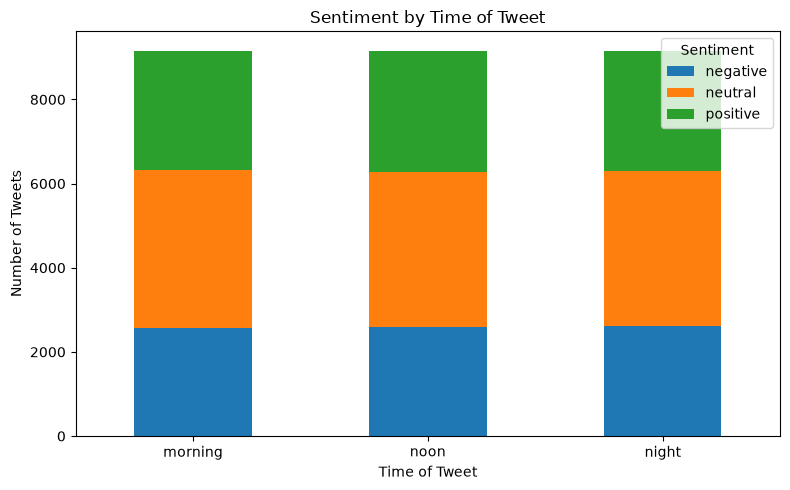

In [4]:
time_sentiment = pd.crosstab(data['Time of Tweet'], data['sentiment']).reindex(['morning', 'noon', 'night'], fill_value=0)

time_sentiment.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title('Sentiment by Time of Tweet')
plt.xlabel('Time of Tweet')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

**4. Topic Modeling with LDA on Tweets:** The main aim of this task is to use LDA (Latent Dirichlet
Allocation) to discover hidden topics within the tweet dataset and analyze how these topics correlate
with different sentiment classes (positive, neutral, negative). Apply LDA to the text or selected_text
field to identify the most common topics discussed in the tweets. After extracting the topics, categorize
tweets based on the most likely topic and analyze the distribution of sentiment across different topics.
Visualize the topics using word clouds or bar charts to interpret the most frequent words associated
with each topic. 

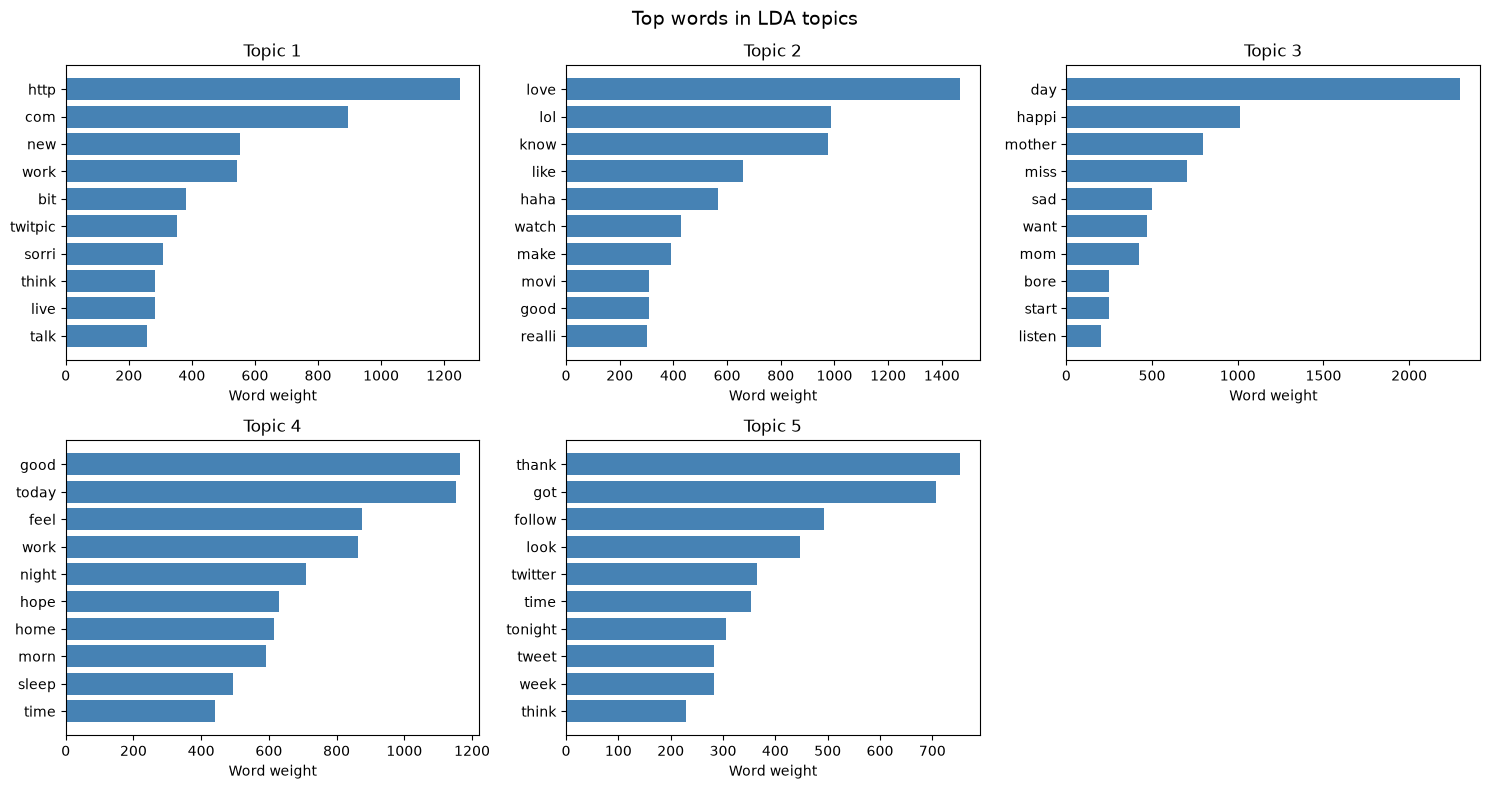

Tweet counts by dominant topic and sentiment:


sentiment,negative,neutral,positive
Topic,,,
1,1362,2599,1097
2,1343,2216,2293
3,1224,1232,1690
4,2268,2638,2019
5,1576,2322,1480


Sentiment distribution within each topic (%):


sentiment,negative,neutral,positive
Topic,,,
1,26.9,51.4,21.7
2,22.9,37.9,39.2
3,29.5,29.7,40.8
4,32.8,38.1,29.2
5,29.3,43.2,27.5


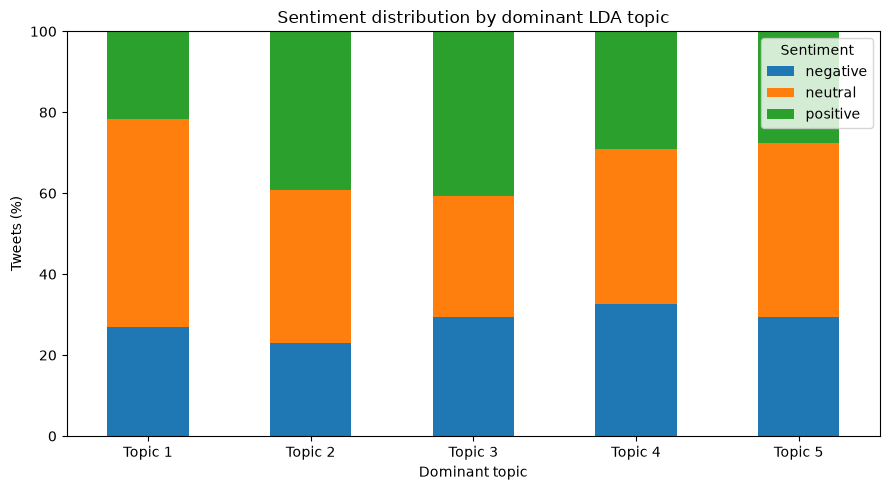

In [5]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from nltk.stem import PorterStemmer
from nltk.corpus import stopwords
import re

def clean_text(text):
    #Function for cleaning the text from numbers, stopwords and non-words.
    text_words_only = re.findall(r'\b[A-Za-z][a-z]{2,}\b', text)
    #Removing stopwords
    stop = stopwords.words("english")
    clean_text = [w for w in text_words_only if w not in stop]
    return clean_text

stemmer = PorterStemmer()

lda_data = data.loc[
    data["text"].notna() & data["sentiment"].notna(), ["text", "sentiment"]
].copy()

tokenized = [
    [stemmer.stem(word) for word in clean_text(str(text).lower())]
    for text in lda_data["text"]
]

tokenized_joined = [" ".join(text) for text in tokenized]

lda_data["text"] = tokenized_joined
lda_data = lda_data.loc[lda_data["text"] != ""].reset_index(drop=True)

vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 1),
    min_df=5,
    max_df=0.95,
    max_features=1000,
)
doc_term_matrix = vectorizer.fit_transform(lda_data["text"])

n_topics = 5
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method="batch",
    max_iter=10,
)
doc_topic_distribution = lda_model.fit_transform(doc_term_matrix)
lda_data["Topic"] = doc_topic_distribution.argmax(axis=1) + 1

feature_names = vectorizer.get_feature_names_out()
n_top_words = 10
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for topic_id, topic_weights in enumerate(lda_model.components_):
    top_word_indices = topic_weights.argsort()[-n_top_words:][::-1]
    top_words = feature_names[top_word_indices]
    top_weights = topic_weights[top_word_indices]
    axes[topic_id].barh(top_words[::-1], top_weights[::-1], color="steelblue")
    axes[topic_id].set_title(f"Topic {topic_id + 1}")
    axes[topic_id].set_xlabel("Word weight")

axes[-1].axis("off")
fig.suptitle("Top words in LDA topics", fontsize=14)
fig.tight_layout()
plt.show()

sentiment_order = [
    label
    for label in ["negative", "neutral", "positive"]
    if label in lda_data["sentiment"].unique()
]
sentiment_order += sorted(
    set(lda_data["sentiment"].unique()) - set(sentiment_order)
)
topic_sentiment_counts = pd.crosstab(
    lda_data["Topic"], lda_data["sentiment"]
).reindex(columns=sentiment_order, fill_value=0)
topic_sentiment_percent = topic_sentiment_counts.div(
    topic_sentiment_counts.sum(axis=1), axis=0
).mul(100)

print("Tweet counts by dominant topic and sentiment:")
display(topic_sentiment_counts)
print("Sentiment distribution within each topic (%):")
display(topic_sentiment_percent.round(1))

topic_sentiment_percent.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Sentiment distribution by dominant LDA topic")
plt.xlabel("Dominant topic")
plt.ylabel("Tweets (%)")
plt.xticks(
    ticks=range(n_topics),
    labels=[f"Topic {topic_id + 1}" for topic_id in range(n_topics)],
    rotation=0,
)
plt.ylim(0, 100)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

**5. Coherence-Based Topic Model Tuning:** The purpose of the task is to optimize LDA’s performance
by tuning the number of topics based on topic coherence. Experiment with different numbers of topics
for LDA (e.g., 5, 10, 15, 20) and use a coherence score (e.g., CV coherence) to evaluate the quality of
the topics. Fine-tune the number of topics based on coherence score to identify the most meaningful
number of topics for the dataset. 

In [6]:
from gensim.models import CoherenceModel
from gensim.corpora import Dictionary

topic_numbers = [5, 10, 15, 20]

texts = [
    vectorizer.build_analyzer()(tweet)
    for tweet in lda_data["text"]
]

coherence_scores = []
lda_models = {}

for k in topic_numbers:
    print(f"Training LDA with {k} topics...")

    model = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        learning_method="batch",
        max_iter=10,
    )

    model.fit(doc_term_matrix)

    topics = []
    for topic_weights in model.components_:
        top_indices = topic_weights.argsort()[-10:][::-1]
        topics.append(feature_names[top_indices].tolist())

    dictionary = Dictionary(texts)
    
    coherence_model = CoherenceModel(
        topics=topics,
        texts=texts,
        dictionary=dictionary,
        coherence="c_v",
        processes=1,
    )

    score = coherence_model.get_coherence()

    coherence_scores.append(score)
    lda_models[k] = model

    print(f"Topics: {k}, CV coherence: {score:.4f}")

results = pd.DataFrame({
    "Number of topics": topic_numbers,
    "CV coherence": coherence_scores
})

display(results.sort_values("CV coherence", ascending=False))

best_k = topic_numbers[coherence_scores.index(max(coherence_scores))]
best_lda_model = lda_models[best_k]

print(f"Best number of topics: {best_k}")
print(f"Highest CV coherence: {max(coherence_scores):.4f}")

Training LDA with 5 topics...
Topics: 5, CV coherence: 0.3836
Training LDA with 10 topics...
Topics: 10, CV coherence: 0.3910
Training LDA with 15 topics...
Topics: 15, CV coherence: 0.3272
Training LDA with 20 topics...
Topics: 20, CV coherence: 0.3022


,Number of topics,CV coherence
1,10,0.390951
0,5,0.383561
2,15,0.327175
3,20,0.302184


Best number of topics: 10
Highest CV coherence: 0.3910


**6. Word Embeddings for Topic Similarity:** The aim of this task is to use Word2Vec or BERT-based
embeddings to analyze the similarity between different topics extracted via LDA (Task 4). Generate
word embeddings for the most frequent words in each LDA topic using Word2Vec or BERT. Calculate
the cosine similarity between different topics based on their word embeddings to see which topics are
semantically similar. Visualize the similarity between topics using heatmaps or dendrograms. 

In [7]:
from gensim.models import Word2Vec
from sklearn.metrics.pairwise import cosine_similarity


w2v_model = Word2Vec(
    sentences=tokenized,
    vector_size=100,
    window=3,
    min_count=1,
    epochs=10)



In [8]:
topics = []
for topic_id, topic_weights in enumerate(lda_model.components_):
    top_word_indices = topic_weights.argsort()[-n_top_words:][::-1]
    topics.append(feature_names[top_word_indices].tolist())

print(topics)

def topic_avg_similarity(topic1, topic2):
    #Takes in already W2V topics
    total = 0
    for v_t1 in topic1: 
        for v_t2 in topic2:
            sim = cosine_similarity(v_t1.reshape(1, -1), v_t2.reshape(1, -1))[0, 0]
            total = total + sim
    return total / (len(topic1) * len(topic2))

def topic_similarity_avgvec(topic1, topic2): 
    #Takes in already W2V topics
    avg_t1 = np.mean(topic1, axis=0)
    avg2_t2 = np.mean(topic2, axis=0)
    sim = sim = cosine_similarity(avg_t1.reshape(1, -1), avg2_t2.reshape(1, -1))[0, 0]
    return sim

w2v_topics = [[w2v_model.wv[word] for word in topic] for topic in topics]

avgsimilarity_matrix = np.zeros((n_topics, n_topics))

for i in range(n_topics):
    for j in range(n_topics):
        if w2v_topics[i] and w2v_topics[j]:
            avgsimilarity_matrix[i, j] = topic_avg_similarity(
                w2v_topics[i], w2v_topics[j]
            )
        else:
            avgsimilarity_matrix[i, j] = np.nan




labels = [f"Topic {i + 1}" for i in range(n_topics)]

topic_avgsimilarities = pd.DataFrame(
    avgsimilarity_matrix,
    index=labels,
    columns=labels
)

avgvec_sim_matrix =  np.zeros((n_topics, n_topics))

for i in range(n_topics):
    for j in range(n_topics):
        if w2v_topics[i] and w2v_topics[j]:
            avgvec_sim_matrix[i, j] = topic_similarity_avgvec(
                w2v_topics[i], w2v_topics[j]
            )
        else:
            avgvec_sim_matrix[i, j] = np.nan

[['http', 'com', 'new', 'work', 'bit', 'twitpic', 'sorri', 'think', 'live', 'talk'], ['love', 'lol', 'know', 'like', 'haha', 'watch', 'make', 'movi', 'good', 'realli'], ['day', 'happi', 'mother', 'miss', 'sad', 'want', 'mom', 'bore', 'start', 'listen'], ['good', 'today', 'feel', 'work', 'night', 'hope', 'home', 'morn', 'sleep', 'time'], ['thank', 'got', 'follow', 'look', 'twitter', 'time', 'tonight', 'tweet', 'week', 'think']]


         Topic 1  Topic 2  Topic 3  Topic 4  Topic 5
Topic 1    0.639    0.639    0.614    0.560    0.617
Topic 2    0.639    0.780    0.715    0.693    0.695
Topic 3    0.614    0.715    0.751    0.717    0.670
Topic 4    0.560    0.693    0.717    0.796    0.688
Topic 5    0.617    0.695    0.670    0.688    0.720


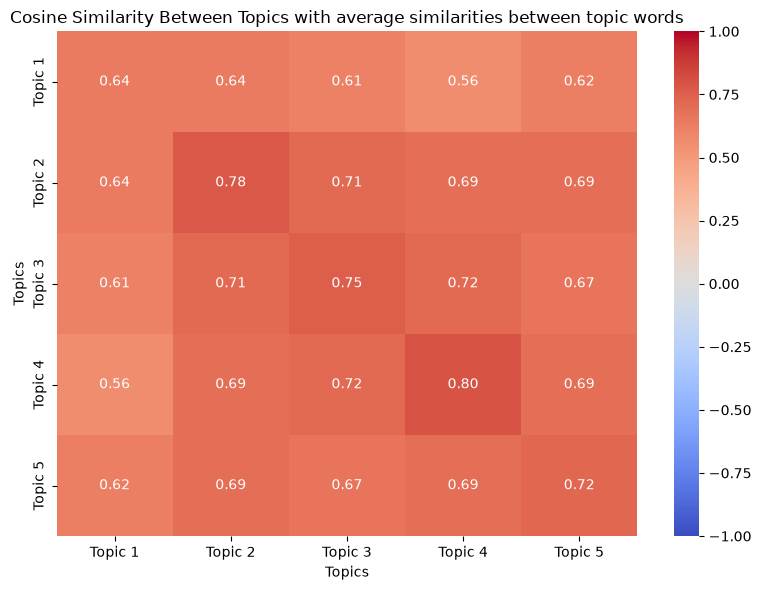

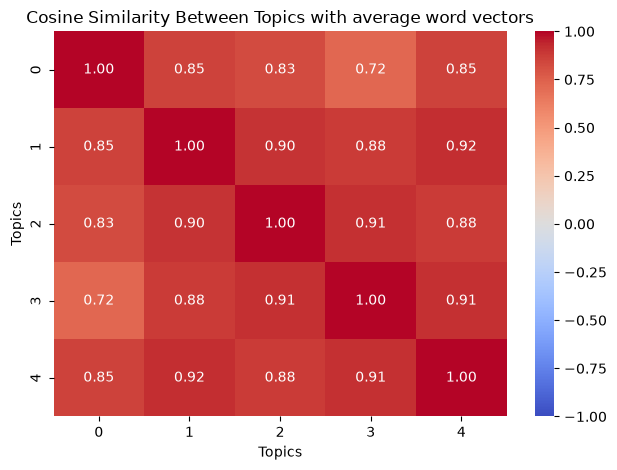

In [9]:

print(topic_avgsimilarities.round(3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    topic_avgsimilarities,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Cosine Similarity Between Topics with average similarities between topic words")
plt.xlabel("Topics")
plt.ylabel("Topics")
plt.tight_layout()
plt.show()


sns.heatmap(
    avgvec_sim_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Cosine Similarity Between Topics with average word vectors")
plt.xlabel("Topics")
plt.ylabel("Topics")
plt.tight_layout()
plt.show()

**7. Topic Sentiment Evolution with Transformer Embeddings:**
In this task we want to combine transformer-generated embeddings (e.g., BERT embeddings) with LDA to improve topic extraction and sentiment analysis. Generate sentence embeddings for each tweet using a transformer model like BERT. Use these embeddings as input for an LDA variant that works with dense vectors (e.g., BERTopic). Analyze the resulting topics and their sentiment evolution, paying close attention to how transformer embeddings impact the quality and coherence of topics.

In [10]:
from transformers import AutoTokenizer, AutoModel

bert_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
bert_model = AutoModel.from_pretrained("bert-base-uncased")

c:\Users\jaakk\dev\NLP_Final_Project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1845.07it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loadi

In [11]:
import numpy as np
import re
import torch
from nltk.corpus import stopwords

# Keep the texts and sentiment labels together and in the same order.
bert_data = data.loc[
    data["text"].notna() & data["sentiment"].notna(),
    ["text", "sentiment"],
].copy()

stop_words = set(stopwords.words("english"))
bert_data["text"] = bert_data["text"].map(
    lambda text: " ".join(
        word
        for word in re.findall(r"[A-Za-z]{3,}", str(text).lower())
        if word not in stop_words
    )
)
bert_data = bert_data.loc[bert_data["text"].ne("")].reset_index(drop=True)
texts = bert_data["text"].tolist()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model = bert_model.to(device)
bert_model.eval()

embedding_batches = []

with torch.inference_mode():
    for start in range(0, len(texts), 32):
        batch_texts = texts[start : start + 32]

        inputs = bert_tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=128,
        )
        inputs = {name: tensor.to(device) for name, tensor in inputs.items()}

        token_vectors = bert_model(**inputs).last_hidden_state
        attention_mask = inputs["attention_mask"].unsqueeze(-1)

        # Average token vectors, ignoring padding tokens.
        sentence_vectors = (
            (token_vectors * attention_mask).sum(dim=1)
            / attention_mask.sum(dim=1).clamp(min=1)
        )

        # Optional: unit-length vectors are convenient for cosine similarity.
        sentence_vectors = torch.nn.functional.normalize(sentence_vectors, p=2, dim=1)
        embedding_batches.append(sentence_vectors.cpu().numpy())

embeddings = np.concatenate(embedding_batches, axis=0)

In [12]:
from bertopic import BERTopic

topic_model = BERTopic(min_topic_size=20, verbose=True)
topics, _ = topic_model.fit_transform(texts, embeddings)
bert_data["topic"] = topics

2026-10-24 18:21:31,816 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-24 18:21:48,881 - BERTopic - Dimensionality - Completed ✓
2026-10-24 18:21:48,883 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-24 18:21:51,197 - BERTopic - Cluster - Completed ✓
2026-10-24 18:21:51,197 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-24 18:21:51,350 - BERTopic - Representation - Completed ✓


Outliers: 16,432 / 27,376 (60.0%)
Largest BERTopic clusters:


,Topic,Count,Name,Representation
1,0,3218,0_http_com_twitpic_twitter,"[http, com, twitpic, twitter, tinyurl, tweet, ..."
2,1,939,1_trek_star_love_show,"[trek, star, love, show, song, movie, new, wat..."
3,2,493,2_haha_hahaha_hahah_hahahaha,"[haha, hahaha, hahah, hahahaha, hahahahaha, ye..."
4,3,451,3_lol_aint_gettin_cuz,"[lol, aint, gettin, cuz, jus, yea, bout, thats..."
5,4,432,4_ice_cream_yummy_cheese,"[ice, cream, yummy, cheese, yum, eating, choco..."
6,5,401,5_dont_didnt_cant_thats,"[dont, didnt, cant, thats, isnt, doesnt, wasnt..."
7,6,334,6_sho_gov_chillin_fair,"[sho, gov, chillin, fair, working, tell, link,..."
8,7,325,7_would_know_thought_could,"[would, know, thought, could, think, like, wan..."
9,8,291,8_even_see_like_really,"[even, see, like, really, also, still, though,..."
10,9,198,9_last_friday_work_night,"[last, friday, work, night, class, tomorrow, t..."


Top-term diversity: 76.8%
C_V coherence on the same documents — BERTopic: 0.403; LDA (10 topics): 0.394
Sentiment distribution within the 10 largest topics (%):


sentiment,negative,neutral,positive
topic,,,
0,23.6,46.2,30.1
1,19.2,37.9,42.9
2,15.8,37.9,46.2
3,37.0,44.3,18.6
4,19.0,44.0,37.0
5,46.6,39.7,13.7
6,18.0,73.7,8.4
7,36.9,46.5,16.6
8,34.4,34.4,31.3


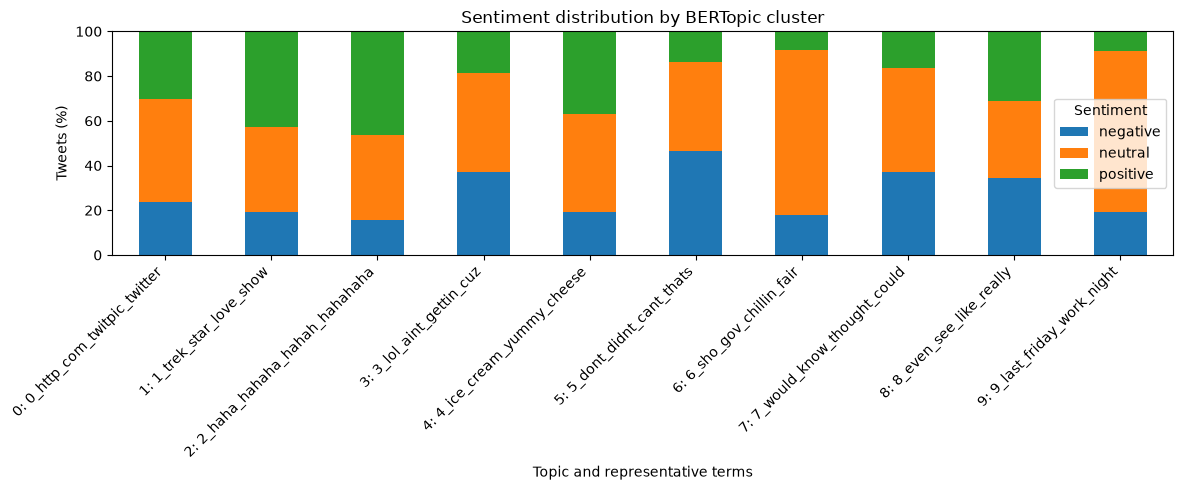

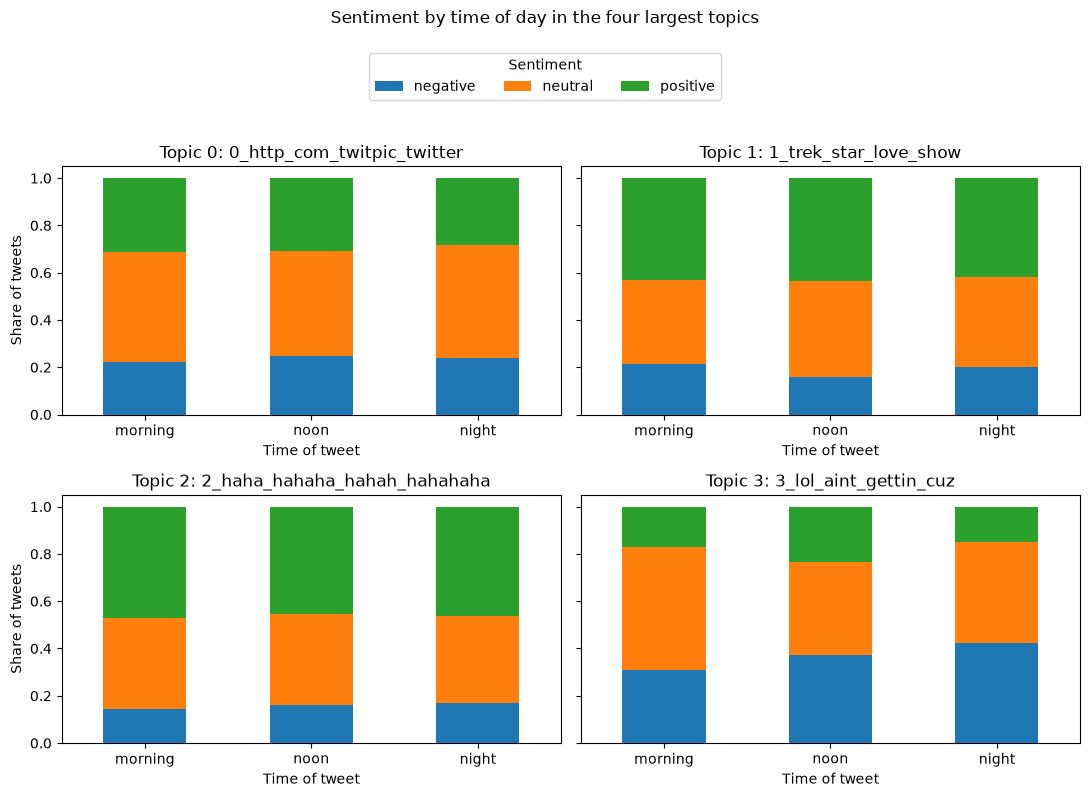

In [13]:
topic_info = topic_model.get_topic_info()
non_outlier_info = topic_info.loc[topic_info["Topic"] != -1].copy()
outlier_count = int(topic_info.loc[topic_info["Topic"] == -1, "Count"].sum())

print(f"Outliers: {outlier_count:,} / {len(bert_data):,} ({outlier_count / len(bert_data):.1%})")
print("Largest BERTopic clusters:")
display(non_outlier_info[["Topic", "Count", "Name", "Representation"]].head(10))

coherence_texts = [
    [stemmer.stem(word) for word in vectorizer.build_analyzer()(text)]
    for text in bert_data["text"]
]
coherence_dictionary = Dictionary(coherence_texts)
bert_topic_words = [
    [stemmer.stem(word) for word, _ in topic_model.get_topic(topic_id)[:10]]
    for topic_id in non_outlier_info["Topic"]
]
lda_topic_words = [
    feature_names[weights.argsort()[-10:][::-1]].tolist()
    for weights in best_lda_model.components_
]

bert_coherence = CoherenceModel(
    topics=bert_topic_words,
    texts=coherence_texts,
    dictionary=coherence_dictionary,
    coherence="c_v",
    processes=1,
).get_coherence()
lda_coherence = CoherenceModel(
    topics=lda_topic_words,
    texts=coherence_texts,
    dictionary=coherence_dictionary,
    coherence="c_v",
    processes=1,
).get_coherence()
unique_terms = len(set(word for topic in bert_topic_words for word in topic))
total_terms = sum(len(topic) for topic in bert_topic_words)
print(f"Top-term diversity: {unique_terms / total_terms:.1%}")
print(f"C_V coherence on the same documents — BERTopic: {bert_coherence:.3f}; LDA ({best_k} topics): {lda_coherence:.3f}")

sentiment_order = [
    label for label in ["negative", "neutral", "positive"]
    if label in bert_data["sentiment"].unique()
]
topic_sentiment = pd.crosstab(
    bert_data["topic"], bert_data["sentiment"], normalize="index"
).reindex(columns=sentiment_order, fill_value=0)
top_topic_ids = non_outlier_info.nlargest(10, "Count")["Topic"]
top_sentiment = topic_sentiment.loc[top_topic_ids].mul(100).round(1)
print("Sentiment distribution within the 10 largest topics (%):")
display(top_sentiment)

topic_names = non_outlier_info.set_index("Topic")["Name"]
top_sentiment.index = [f"{topic_id}: {topic_names[topic_id]}" for topic_id in top_topic_ids]
top_sentiment.plot(kind="bar", stacked=True, figsize=(12, 5))
plt.title("Sentiment distribution by BERTopic cluster")
plt.xlabel("Topic and representative terms")
plt.ylabel("Tweets (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

time_data = data.loc[
    data["text"].notna() & data["sentiment"].notna(), ["text", "Time of Tweet"]
].copy()
time_data["text"] = time_data["text"].map(
    lambda text: " ".join(
        word for word in re.findall(r"[A-Za-z]{3,}", str(text).lower())
        if word not in stop_words
    )
)
time_data = time_data.loc[time_data["text"].ne("")].reset_index(drop=True)
if not time_data["text"].equals(bert_data["text"]):
    raise ValueError("Time-of-day labels do not align with the embedded documents.")

bert_data["Time of Tweet"] = time_data["Time of Tweet"]
time_order = [period for period in ["morning", "noon", "night"] if period in time_data["Time of Tweet"].unique()]
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
for ax, topic_id in zip(axes.flat, non_outlier_info.nlargest(4, "Count")["Topic"]):
    topic_rows = bert_data.loc[bert_data["topic"] == topic_id]
    by_time = pd.crosstab(
        topic_rows["Time of Tweet"], topic_rows["sentiment"], normalize="index"
    ).reindex(index=time_order, columns=sentiment_order, fill_value=0)
    by_time.plot(kind="bar", stacked=True, ax=ax, legend=False)
    ax.set_title(f"Topic {topic_id}: {topic_names[topic_id]}")
    ax.set_xlabel("Time of tweet")
    ax.set_ylabel("Share of tweets")
    ax.tick_params(axis="x", rotation=0)
for ax in axes.flat[4:]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.suptitle("Sentiment by time of day in the four largest topics", y=0.99)
fig.legend(
    handles, labels, title="Sentiment", loc="upper center",
    bbox_to_anchor=(0.5, 0.945), ncol=len(sentiment_order),
)
fig.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()


**8. Sentiment Analysis Using Transformers**: Leverage pre-trained transformer models such as BERT, RoBERTa, and DistilBERT for sentiment classification (positive, neutral, or negative). Fine-tune these models on the train dataset using the text and selected_text (which represents the portion of the tweet most relevant to the sentiment) columns separately. Then, conduct fine-tuning by training on the labeled sentiment data on train data and test the result on Test data. Additionally, experiment with different variants of BERT (e.g., BERT-large vs. BERT-base) to improve accuracy. Compare the performance of transformer models (BERT, RoBERTa) against other NLP techniques, such as TF-IDF + Logistic Regression, to demonstrate the advantage of transformers in this sentiment classification task.

In [28]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer, TrainingArguments, Trainer
import numpy as np
from datasets import Dataset, DatasetDict
from sklearn.model_selection import train_test_split

train_text = data[["text", "sentiment"]].dropna(subset=["text"]).rename(columns={"sentiment": "labels"}).copy()
selected_text = data[["selected_text", "sentiment"]].rename(columns={"sentiment": "labels"}).copy()

test = pd.read_csv("test.csv", encoding="latin1")
test_text = test[["text", "sentiment"]].dropna(subset=["text"]).rename(columns={"sentiment": "labels"}).copy()

train_text["labels"] = train_text["labels"].map({
    "negative": 0,
    "neutral": 1,
    "positive": 2
})

test_text["labels"] = test_text["labels"].map({
    "negative": 0,
    "neutral": 1,
    "positive": 2
})

selected_text["labels"] = selected_text["labels"].map({
    "negative": 0,
    "neutral": 1,
    "positive": 2
})

train_selected, test_selected = train_test_split(
    selected_text,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

#Sopivaksi muokatutu datat
datasets_fulltext = DatasetDict({
    "train": Dataset.from_pandas(train_text),
    "test": Dataset.from_pandas(test_text)
})

datasets_selected = DatasetDict({
    "train": Dataset.from_pandas(train_selected.reset_index(drop=True)),
    "test": Dataset.from_pandas(test_selected.reset_index(drop=True))
})

#Malli tyypit
model_type = ['google-bert/bert-base-uncased', 'FacebookAI/roberta-base', 'distilbert/distilbert-base-uncased', 'google-bert/bert-large-uncased', "vinai/bertweet-base"]

In [29]:
#BERT base
#Muille malleille oon vaan kopioinut saman rakenteen, mutta muuttanut tokenizer ja model mallille omaksi
# Sitten ongelmia voi tulla noissa mallien ajoissa, jos kaikkien kirjastojen versiot ei ole yhteen sopivia
from sklearn.metrics import accuracy_score

#Kerää vaan listaan mallien tarkkuutta
models_acc = []

#Mallin oma tokenisoija
tokenizer = AutoTokenizer.from_pretrained(model_type[0])

#Pre-trained malli
model = AutoModelForSequenceClassification.from_pretrained(model_type[0], num_labels = 3)

# Fine tuunauksen argumentit voisi katsoa parempia argumentteja, mutta nyt defaulttina
training_args = TrainingArguments("test_trainer", 
                                  eval_strategy="epoch", 
                                  per_device_train_batch_size=16,
                                  per_device_eval_batch_size=32,
                                  dataloader_num_workers=2,
                                  fp16=True)

#Funktio jolla saa tokenisoitua aina oikein tietyllöe mallille datan
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=64
    )

# Vaihda tähän kohtaan datasets_fulltext tilalle se datasets_selected niin vaihtaa mallin selected text muutujalle
tokenized_datasets = datasets_fulltext.map(
    tokenize_function,
    batched=True
)

# Pienempi data testaamiselle muutta range() arvoja niin saat eri kokoiseksi
#small_train_dataset = tokenized_datasets["train"].shuffle(seed=42).select(range(200))
#small_eval_dataset = tokenized_datasets["test"].shuffle(seed=42).select(range(200))
full_train_dataset = tokenized_datasets["train"]
full_eval_dataset = tokenized_datasets["test"]

# Tuning
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=full_train_dataset,
    eval_dataset=full_eval_dataset
)
trainer.train()

# Funktio joka laskee tarkkuuden
def accuracy(trainer, data):
    label_values = trainer.predict(data)
    predictions = np.argmax(label_values.predictions, axis=-1)
    return accuracy_score(label_values.label_ids, predictions)

models_acc.append(("BERT_base", accuracy(trainer, full_eval_dataset)))

#Poistaa mallit muistista
del trainer
del model
del tokenizer


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1708.64it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from 

Epoch,Training Loss,Validation Loss
1,0.546439,0.518839
2,0.376461,0.545160
3,0.206184,0.756285


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.29it/s]


In [30]:
#Robert
tokenizer = AutoTokenizer.from_pretrained(model_type[1])

model = AutoModelForSequenceClassification.from_pretrained(model_type[1], num_labels = 3)

training_args = TrainingArguments("test_trainer", 
                                  eval_strategy="epoch", 
                                  per_device_train_batch_size=16,
                                  per_device_eval_batch_size=32,
                                  dataloader_num_workers=2,
                                  fp16=True)

tokenized_datasets = datasets_fulltext.map(
    tokenize_function,
    batched=True
)

# Smaller data set for testitng
#small_train_dataset = tokenized_datasets["train"].shuffle(seed=42).select(range(200))
#small_eval_dataset = tokenized_datasets["test"].shuffle(seed=42).select(range(200))
full_train_dataset = tokenized_datasets["train"]
full_eval_dataset = tokenized_datasets["test"]

# Tuning
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=full_train_dataset,
    eval_dataset=full_eval_dataset
)
trainer.train()

models_acc.append(("RoBERT", accuracy(trainer, full_eval_dataset)))

del trainer
del model
del tokenizer

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1273.76it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Map: 100%|██████████| 3534/3534 [00:00<00:00, 72184.93 examples/s]


Epoch,Training Loss,Validation Loss
1,0.570257,0.514560
2,0.444384,0.533594
3,0.334803,0.584332


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.26it/s]


In [31]:
#DISTILBERT
tokenizer = AutoTokenizer.from_pretrained(model_type[2])

model = AutoModelForSequenceClassification.from_pretrained(model_type[2], num_labels = 3)

training_args = TrainingArguments("test_trainer", 
                                  eval_strategy="epoch", 
                                  per_device_train_batch_size=16,
                                  per_device_eval_batch_size=32,
                                  dataloader_num_workers=2,
                                  fp16=True)

tokenized_datasets = datasets_fulltext.map(
    tokenize_function,
    batched=True
)

# Smaller data set for testitng
#small_train_dataset = tokenized_datasets["train"].shuffle(seed=42).select(range(200))
#small_eval_dataset = tokenized_datasets["test"].shuffle(seed=42).select(range(200))
full_train_dataset = tokenized_datasets["train"]
full_eval_dataset = tokenized_datasets["test"]

# Tuning
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=full_train_dataset,
    eval_dataset=full_eval_dataset
)
trainer.train()

models_acc.append(("DistilBERT", accuracy(trainer, full_eval_dataset)))

del trainer
del model
del tokenizer

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 3837.04it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Map: 100%|██████████| 3534/3534 [00:00<00:00, 60252.55 examples/s]


Epoch,Training Loss,Validation Loss
1,0.544395,0.516275
2,0.381916,0.582197
3,0.236380,0.720903


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  6.24it/s]


In [32]:
#BERT LARGE
tokenizer = AutoTokenizer.from_pretrained(model_type[3])

model = AutoModelForSequenceClassification.from_pretrained(model_type[3], num_labels = 3)

training_args = TrainingArguments("test_trainer", 
                                  eval_strategy="epoch", 
                                  per_device_train_batch_size=16,
                                  per_device_eval_batch_size=32,
                                  dataloader_num_workers=2,
                                  fp16=True)

tokenized_datasets = datasets_fulltext.map(
    tokenize_function,
    batched=True
)

# Smaller data set for testitng
#small_train_dataset = tokenized_datasets["train"].shuffle(seed=42).select(range(200))
#small_eval_dataset = tokenized_datasets["test"].shuffle(seed=42).select(range(200))
full_train_dataset = tokenized_datasets["train"]
full_eval_dataset = tokenized_datasets["test"]

# Tuning
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=full_train_dataset,
    eval_dataset=full_eval_dataset
)
trainer.train()

models_acc.append(("BERT LARGE", accuracy(trainer, full_eval_dataset)))

del trainer
del model
del tokenizer

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 883.39it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-large-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from 

Epoch,Training Loss,Validation Loss
1,1.103838,1.094898
2,1.096319,1.088818
3,1.095829,1.087010


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.64it/s]


In [33]:
#BERTtweet
tokenizer = AutoTokenizer.from_pretrained(model_type[4])

model = AutoModelForSequenceClassification.from_pretrained(model_type[4], num_labels = 3)

training_args = TrainingArguments("test_trainer", 
                                  eval_strategy="epoch", 
                                  per_device_train_batch_size=16,
                                  per_device_eval_batch_size=32,
                                  dataloader_num_workers=2,
                                  fp16=True)

tokenized_datasets = datasets_fulltext.map(
    tokenize_function,
    batched=True
)

# Smaller data set for testitng
#small_train_dataset = tokenized_datasets["train"].shuffle(seed=42).select(range(200))
#small_eval_dataset = tokenized_datasets["test"].shuffle(seed=42).select(range(200))
full_train_dataset = tokenized_datasets["train"]
full_eval_dataset = tokenized_datasets["test"]

# Tuning
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=full_train_dataset,
    eval_dataset=full_eval_dataset
)
trainer.train()

models_acc.append(("BERTtweet", accuracy(trainer, full_eval_dataset)))

del trainer
del model
del tokenizer

Loading weights: 100%|██████████| 197/197 [00:00<?, ?it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/bertweet-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the ch

Epoch,Training Loss,Validation Loss
1,0.533339,0.492770
2,0.396270,0.522913
3,0.267614,0.560168


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.48it/s]


In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

#TFIDF logistinen regressio
tfidfconventer = TfidfVectorizer(max_features=1000, min_df=1, max_df=0.7, stop_words=stopwords.words('english'))

tfidf_train = tfidfconventer.fit_transform(train_text["text"])
tfidf_test = tfidfconventer.fit_transform(test_text["text"])

lrmodel = LogisticRegression(max_iter=1000)

lrmodel.fit(tfidf_train, train_text["labels"])

predictions = lrmodel.predict(tfidf_test)

acc = accuracy_score(test_text['labels'], predictions)

models_acc.append(("TFIDF LR-model", acc))

In [35]:
print(models_acc)

[('BERT_base', 0.7917374080362196), ('RoBERT', 0.7928692699490663), ('DistilBERT', 0.787209960384833), ('BERT LARGE', 0.4046406338426712), ('BERTtweet', 0.811262026032824), ('TFIDF LR-model', 0.41992076966610076)]


**9. Multi-modal Analysis with Metadata:**
Incorporate user demographic features (Age of User, Country, Population 2020, Density (P/Km²)) along with tweet text in the model. Train a multi-input model where one branch processes the textual content (using transformers) and another branch processes demographic and geographical features of the users. Combine the results to make a final sentiment prediction. Evaluate the importance of each feature using SHAP values or feature importance analysis to understand the contribution of text versus demographic data to the overall sentiment prediction.

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 26713.61it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1, loss: 0.6055
Validation accuracy (text + metadata): 0.788
Text-only accuracy: 0.788
Metadata-only accuracy: 0.284


,Feature,Accuracy drop after permutation
2,Population -2020,0.000000
0,Age of User,0.000182
1,Country,0.000182
3,Density (P/Km²),0.000364


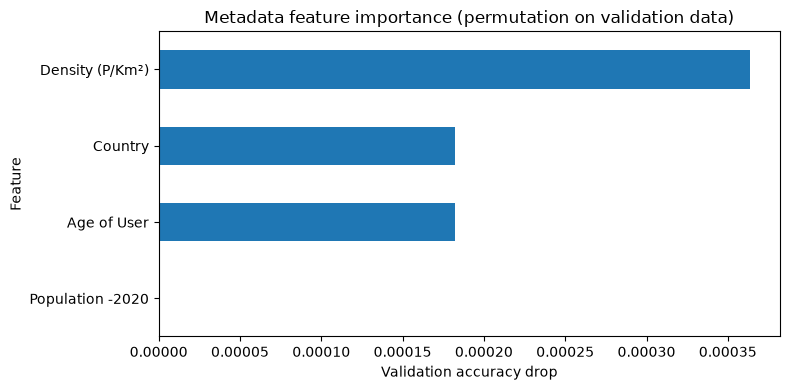

In [36]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModel, AutoTokenizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

multimodal_rows = data[[
    "text", "sentiment", "Age of User", "Country",
    "Population -2020", "Density (P/Km²)"
]].dropna(subset=["text", "sentiment"]).reset_index(drop=True)

label_map = {"negative": 0, "neutral": 1, "positive": 2}
multimodal_rows["labels"] = multimodal_rows["sentiment"].map(label_map)
multimodal_rows = multimodal_rows.dropna(subset=["labels"]).reset_index(drop=True)

train_indices, eval_indices = train_test_split(
    np.arange(len(multimodal_rows)),
    test_size=0.2,
    random_state=42,
    stratify=multimodal_rows["labels"],
)
train_rows = multimodal_rows.iloc[train_indices]
eval_rows = multimodal_rows.iloc[eval_indices]

categorical_columns = ["Age of User", "Country"]
numeric_columns = ["Population -2020", "Density (P/Km²)"]
metadata_train = pd.get_dummies(
    train_rows[categorical_columns + numeric_columns].copy(),
    columns=categorical_columns,
    dtype=float,
)
metadata_eval = pd.get_dummies(
    eval_rows[categorical_columns + numeric_columns].copy(),
    columns=categorical_columns,
    dtype=float,
).reindex(columns=metadata_train.columns, fill_value=0)

for column in numeric_columns:
    metadata_train[column] = pd.to_numeric(metadata_train[column], errors="coerce")
    metadata_eval[column] = pd.to_numeric(metadata_eval[column], errors="coerce")
metadata_medians = metadata_train[numeric_columns].median()
metadata_train[numeric_columns] = metadata_train[numeric_columns].fillna(metadata_medians)
metadata_eval[numeric_columns] = metadata_eval[numeric_columns].fillna(metadata_medians)
metadata_mean = metadata_train[numeric_columns].mean()
metadata_std = metadata_train[numeric_columns].std().replace(0, 1)
metadata_train[numeric_columns] = (metadata_train[numeric_columns] - metadata_mean) / metadata_std
metadata_eval[numeric_columns] = (metadata_eval[numeric_columns] - metadata_mean) / metadata_std

multimodal_tokenizer = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")
train_tokens = multimodal_tokenizer(
    train_rows["text"].tolist(), padding="max_length", truncation=True,
    max_length=64, return_tensors="pt"
)
eval_tokens = multimodal_tokenizer(
    eval_rows["text"].tolist(), padding="max_length", truncation=True,
    max_length=64, return_tensors="pt"
)

train_dataset = TensorDataset(
    train_tokens["input_ids"], train_tokens["attention_mask"],
    torch.tensor(metadata_train.to_numpy(), dtype=torch.float32),
    torch.tensor(train_rows["labels"].to_numpy(), dtype=torch.long),
)
eval_metadata = torch.tensor(metadata_eval.to_numpy(), dtype=torch.float32)
eval_dataset = TensorDataset(
    eval_tokens["input_ids"], eval_tokens["attention_mask"], eval_metadata,
    torch.tensor(eval_rows["labels"].to_numpy(), dtype=torch.long),
)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class MultimodalClassifier(nn.Module):
    def __init__(self, metadata_size):
        super().__init__()
        self.text_model = AutoModel.from_pretrained("distilbert/distilbert-base-uncased")
        text_size = self.text_model.config.hidden_size
        self.classifier = nn.Sequential(
            nn.Linear(text_size + metadata_size, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 3),
        )

    def forward(self, input_ids, attention_mask, metadata, use_text=True, use_metadata=True):
        text_output = self.text_model(input_ids=input_ids, attention_mask=attention_mask)
        text_features = text_output.last_hidden_state[:, 0, :]
        if not use_text:
            text_features = torch.zeros_like(text_features)
        if not use_metadata:
            metadata = torch.zeros_like(metadata)
        combined_features = torch.cat((text_features, metadata), dim=1)
        return self.classifier(combined_features)

multimodal_model = MultimodalClassifier(metadata_train.shape[1]).to(device)
optimizer = torch.optim.AdamW(multimodal_model.parameters(), lr=2e-5)
loss_function = nn.CrossEntropyLoss()

for epoch in range(1):
    multimodal_model.train()
    total_loss = 0
    for input_ids, attention_mask, metadata_batch, labels in train_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        metadata_batch = metadata_batch.to(device)
        labels = labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = multimodal_model(input_ids, attention_mask, metadata_batch)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch + 1}, loss: {total_loss / len(train_loader):.4f}")

def multimodal_accuracy(use_text=True, use_metadata=True, metadata_values=None):
    multimodal_model.eval()
    predictions = []
    actual = []
    with torch.inference_mode():
        for start in range(0, len(eval_dataset), 32):
            input_ids, attention_mask, metadata_batch, labels = eval_dataset[start:start + 32]
            if metadata_values is not None:
                metadata_batch = metadata_values[start:start + 32]
            logits = multimodal_model(
                input_ids.to(device), attention_mask.to(device), metadata_batch.to(device),
                use_text=use_text, use_metadata=use_metadata
            )
            predictions.extend(logits.argmax(dim=1).cpu().tolist())
            actual.extend(labels.tolist())
    return accuracy_score(actual, predictions)

baseline_accuracy = multimodal_accuracy()
print(f"Validation accuracy (text + metadata): {baseline_accuracy:.3f}")
print(f"Text-only accuracy: {multimodal_accuracy(use_metadata=False):.3f}")
print(f"Metadata-only accuracy: {multimodal_accuracy(use_text=False):.3f}")

metadata_groups = {
    "Age of User": [i for i, name in enumerate(metadata_train.columns) if name.startswith("Age of User_")],
    "Country": [i for i, name in enumerate(metadata_train.columns) if name.startswith("Country_")],
    "Population -2020": [metadata_train.columns.get_loc("Population -2020")],
    "Density (P/Km²)": [metadata_train.columns.get_loc("Density (P/Km²)")],
}
importance = []
for feature, columns in metadata_groups.items():
    shuffled_metadata = eval_metadata.clone()
    shuffled_metadata[:, columns] = eval_metadata[
        torch.randperm(len(eval_metadata))
    ][:, columns]
    shuffled_accuracy = multimodal_accuracy(metadata_values=shuffled_metadata)
    importance.append((feature, baseline_accuracy - shuffled_accuracy))

importance = pd.DataFrame(importance, columns=["Feature", "Accuracy drop after permutation"])
importance = importance.sort_values("Accuracy drop after permutation", ascending=True)
display(importance)
importance.plot.barh(
    x="Feature", y="Accuracy drop after permutation", legend=False, figsize=(8, 4)
)
plt.title("Metadata feature importance (permutation on validation data)")
plt.xlabel("Validation accuracy drop")
plt.tight_layout()
plt.show()